# Лабораторная работа №2
## Вариант 18

In [1]:
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mpl_toolkits.mplot3d import Axes3D

OUT = Path("lab2_variant18_outputs")
OUT.mkdir(exist_ok=True)

class Interval:
    def __init__(self, lo, hi=None):
        if hi is None:
            hi = lo
        self.lo = float(lo)
        self.hi = float(hi)
        if self.lo > self.hi:
            self.lo, self.hi = self.hi, self.lo

    @property
    def mid(self):
        return (self.lo + self.hi) / 2

    @property
    def rad(self):
        return (self.hi - self.lo) / 2

    def __repr__(self):
        return f"[{self.lo:.6f}, {self.hi:.6f}]"

    def __add__(self, other):
        other = other if isinstance(other, Interval) else Interval(other)
        return Interval(self.lo + other.lo, self.hi + other.hi)

    __radd__ = __add__

    def __neg__(self):
        return Interval(-self.hi, -self.lo)

    def __sub__(self, other):
        other = other if isinstance(other, Interval) else Interval(other)
        return self + (-other)

    def __rsub__(self, other):
        other = other if isinstance(other, Interval) else Interval(other)
        return other + (-self)

    def __mul__(self, other):
        other = other if isinstance(other, Interval) else Interval(other)
        v = [self.lo*other.lo, self.lo*other.hi, self.hi*other.lo, self.hi*other.hi]
        return Interval(min(v), max(v))

    __rmul__ = __mul__

    def pow_int(self, n):
        if n == 0:
            return Interval(1)
        if n % 2:
            return Interval(self.lo**n, self.hi**n)
        v = [self.lo**n, self.hi**n]
        return Interval(0 if self.lo <= 0 <= self.hi else min(v), max(v))

def sin_interval(X):
    vals = [math.sin(X.lo), math.sin(X.hi)]
    k0 = math.ceil((X.lo - math.pi/2) / math.pi)
    k1 = math.floor((X.hi - math.pi/2) / math.pi)
    for k in range(k0, k1 + 1):
        vals.append(math.sin(math.pi/2 + k*math.pi))
    return Interval(min(vals), max(vals))

def cos_interval(X):
    vals = [math.cos(X.lo), math.cos(X.hi)]
    k0 = math.ceil(X.lo / math.pi)
    k1 = math.floor(X.hi / math.pi)
    for k in range(k0, k1 + 1):
        vals.append(math.cos(k*math.pi))
    return Interval(min(vals), max(vals))

def hausdorff(A, B):
    return max(abs(A.lo - B.lo), abs(A.hi - B.hi))

def hull(*xs):
    return Interval(min(x.lo for x in xs), max(x.hi for x in xs))

def intersection(A, B):
    return Interval(max(A.lo, B.lo), min(A.hi, B.hi))

def mean_1d(f, D, X, c):
    return Interval(f(c)) + D * (X - c)

def baumann_1d(D, X, f):
    p = 0.0 if D.rad == 0 else np.clip(D.mid / D.rad, -1, 1)
    c1 = X.mid - p * X.rad
    c2 = X.mid + p * X.rad
    A = mean_1d(f, D, X, c1)
    B = mean_1d(f, D, X, c2)
    return p, c1, c2, intersection(A, B)

def row(name, I, exact):
    return [name, f"[{I.lo:.6f}, {I.hi:.6f}]", I.rad, hausdorff(I, exact)]


## 1. Общая функция $f_1(x)$

In [2]:
X1 = Interval(0, 3)
true1 = Interval(-2, 2)

def f1(x):
    return x**3 - 3*x**2 + 2

nat1 = X1.pow_int(3) - 3*X1.pow_int(2) + 2
T = X1 - 1
eq1 = T * (T.pow_int(2) - 3)
D1 = 3*X1.pow_int(2) - 6*X1
centers1 = [0, 0.75, 1.5, 2.25, 3]

def slope1(X, c):
    return X.pow_int(2) + c*X + c*c - 3*(X + c)

rows1 = [row("Точная область", true1, true1), row("Естественная форма", nat1, true1), row("Эквивалентная форма", eq1, true1)]
for c in centers1:
    mv = mean_1d(f1, D1, X1, c)
    sl = Interval(f1(c)) + slope1(X1, c)*(X1-c)
    rows1 += [row(f"Mean, c={c}", mv, true1), row(f"Slope, c={c}", sl, true1)]
p1, bc11, bc12, bic1 = baumann_1d(D1, X1, f1)
rows1.append(row("Baumann", bic1, true1))
df1 = pd.DataFrame(rows1, columns=["Метод", "F(X)", "rad F(X)", "d_H"])
display(df1)
print("Baumann:", p1, bc11, bc12, bic1)
print("L_exact =", 9.0, "; L_exact*rad(X) =", 9*X1.rad)
print("L_expr =", 45.0, "; L_expr*rad(X) =", 45*X1.rad)


,Метод,F(X),rad F(X),d_H
0,Точная область,"[-2.000000, 2.000000]",2.00000,0.000000
1,Естественная форма,"[-25.000000, 29.000000]",27.00000,27.000000
2,Эквивалентная форма,"[-6.000000, 3.000000]",4.50000,4.000000
3,"Mean, c=0","[-52.000000, 83.000000]",67.50000,81.000000
4,"Slope, c=0","[-25.000000, 29.000000]",27.00000,27.000000
5,"Mean, c=0.75","[-39.765625, 61.484375]",50.62500,59.484375
6,"Slope, c=0.75","[-23.312500, 22.250000]",22.78125,21.312500
7,"Mean, c=1.5","[-41.875000, 39.125000]",40.50000,39.875000
8,"Slope, c=1.5","[-18.250000, 15.500000]",16.87500,16.250000
9,"Mean, c=2.25","[-62.546875, 38.703125]",50.62500,60.546875


Baumann: 0.2 1.2 1.8 [-32.992000, 30.512000]
L_exact = 9.0 ; L_exact*rad(X) = 13.5
L_expr = 45.0 ; L_expr*rad(X) = 67.5


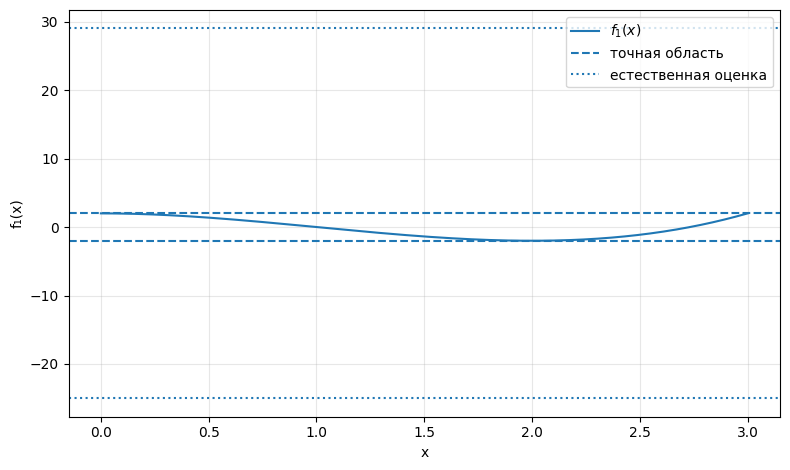

In [3]:
xx = np.linspace(0, 3, 600)
yy = f1(xx)
plt.figure(figsize=(8, 4.8))
plt.plot(xx, yy, label=r"$f_1(x)$")
plt.axhline(true1.lo, linestyle="--", label="точная область")
plt.axhline(true1.hi, linestyle="--")
plt.axhline(nat1.lo, linestyle=":", label="естественная оценка")
plt.axhline(nat1.hi, linestyle=":")
plt.xlabel("x"); plt.ylabel("f₁(x)"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(OUT/"f1.png", dpi=180)
plt.show()


## 2. Индивидуальная функция $f_2(x)$

In [4]:
X2 = Interval(-1.5, 1.5)

def f2(x):
    return x**3 + np.sin(x) - 1

true2 = Interval(f2(X2.lo), f2(X2.hi))
nat2 = X2.pow_int(3) + sin_interval(X2) - 1
eq2 = X2 * X2.pow_int(2) + sin_interval(X2) - 1
D2 = 3*X2.pow_int(2) + cos_interval(X2)
centers2 = [-1.5, -0.75, 0, 0.75, 1.5]

def slope2(X, c):
    return X.pow_int(2) + c*X + c*c + cos_interval(X)

rows2 = [row("Точная область", true2, true2), row("Естественная форма", nat2, true2), row("Эквивалентная форма", eq2, true2)]
for c in centers2:
    mv = mean_1d(f2, D2, X2, c)
    sl = Interval(float(f2(c))) + slope2(X2, c)*(X2-c)
    rows2 += [row(f"Mean, c={c}", mv, true2), row(f"Slope, c={c}", sl, true2)]
p2, bc21, bc22, bic2 = baumann_1d(D2, X2, f2)
rows2.append(row("Baumann", bic2, true2))
df2 = pd.DataFrame(rows2, columns=["Метод", "F(X)", "rad F(X)", "d_H"])
display(df2)
L2_exact = 3*1.5**2 + math.cos(1.5)
print("Baumann:", p2, bc21, bc22, bic2)
print("L_exact =", L2_exact, "; L_exact*rad(X) =", L2_exact*X2.rad)
print("L_expr =", 7.75, "; L_expr*rad(X) =", 7.75*X2.rad)


,Метод,F(X),rad F(X),d_H
0,Точная область,"[-5.372495, 3.372495]",4.372495,0.000000
1,Естественная форма,"[-5.372495, 3.372495]",4.372495,0.000000
2,Эквивалентная форма,"[-5.372495, 3.372495]",4.372495,0.000000
3,"Mean, c=-1.5","[-5.372495, 17.877505]",11.625000,14.505010
4,"Slope, c=-1.5","[-5.372495, 17.877505]",11.625000,14.505010
5,"Mean, c=-0.75","[-7.916014, 15.333986]",11.625000,11.961491
6,"Slope, c=-0.75","[-5.806639, 9.005861]",7.406250,5.633366
7,"Mean, c=0","[-12.625000, 10.625000]",11.625000,7.252505
8,"Slope, c=0","[-5.875000, 3.875000]",4.875000,0.502505
9,"Mean, c=0.75","[-17.333986, 5.916014]",11.625000,11.961491


Baumann: 1.0 -1.5 1.5 [-5.372495, 3.372495]
L_exact = 6.820737201667703 ; L_exact*rad(X) = 10.231105802501554
L_expr = 7.75 ; L_expr*rad(X) = 11.625


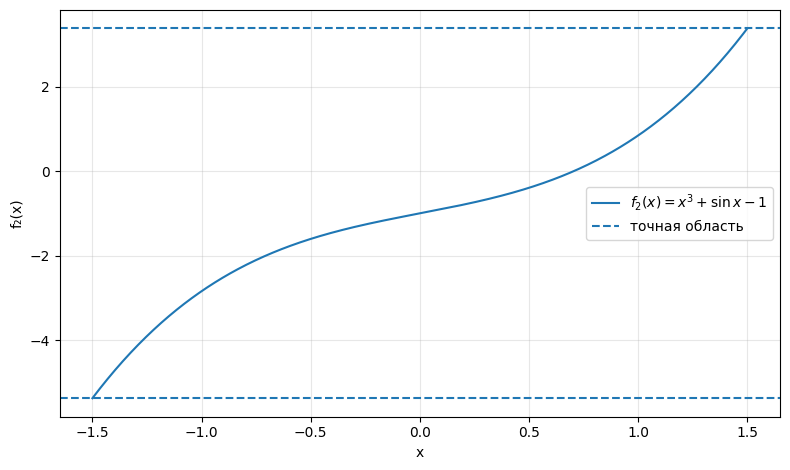

In [5]:
xx = np.linspace(X2.lo, X2.hi, 600)
yy = f2(xx)
plt.figure(figsize=(8, 4.8))
plt.plot(xx, yy, label=r"$f_2(x)=x^3+\sin x-1$")
plt.axhline(true2.lo, linestyle="--", label="точная область")
plt.axhline(true2.hi, linestyle="--")
plt.xlabel("x"); plt.ylabel("f₂(x)"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(OUT/"f2.png", dpi=180)
plt.show()


## 3. Функция двух переменных $f_3(x,y)$

In [6]:
X = Interval(-1, 2)
Y = Interval(-1.5, 1.5)

def f3(x, y):
    return x*x + y**4 - x*y

true3 = Interval(-1/64, 12.0625)
nat3 = X.pow_int(2) + Y.pow_int(4) - X*Y
eq3 = (X - 0.5*Y).pow_int(2) + (Y.pow_int(2) - 1/8).pow_int(2) - 1/64
Dx = 2*X - Y
Dy = 4*Y.pow_int(3) - X

def mean2d(c):
    cx, cy = c
    return Interval(f3(cx, cy)) + Dx*(X-cx) + Dy*(Y-cy)

c_mid = (X.mid, Y.mid)
c_min = (1/(4*math.sqrt(2)), 1/(2*math.sqrt(2)))
mv_mid = mean2d(c_mid)
mv_min = mean2d(c_min)

p_x = np.clip(Dx.mid/Dx.rad, -1, 1)
p_y = np.clip(Dy.mid/Dy.rad, -1, 1)
cA = (X.mid-p_x*X.rad, Y.mid-p_y*Y.rad)
cB = (X.mid+p_x*X.rad, Y.mid+p_y*Y.rad)
bic3 = intersection(mean2d(cA), mean2d(cB))

def nat_f3(Xi, Yi):
    return Xi.pow_int(2) + Yi.pow_int(4) - Xi*Yi

x1 = nat_f3(Interval(X.lo, X.mid), Y)
x2 = nat_f3(Interval(X.mid, X.hi), Y)
split_x = hull(x1, x2)
y1 = nat_f3(X, Interval(Y.lo, Y.mid))
y2 = nat_f3(X, Interval(Y.mid, Y.hi))
split_y = hull(y1, y2)

rows3 = [
    row("Точная область", true3, true3),
    row("Естественная форма", nat3, true3),
    row("Эквивалентная форма", eq3, true3),
    row("Mean, c=mid X", mv_mid, true3),
    row("Mean, c=точка минимума", mv_min, true3),
    row("Baumann", bic3, true3),
    row("Дробление по x", split_x, true3),
    row("Дробление по y", split_y, true3),
]
df3 = pd.DataFrame(rows3, columns=["Метод", "F(X)", "rad F(X)", "d_H"])
display(df3)
print("Dx =", Dx, "; Dy =", Dy)
print("Baumann centers:", cA, cB, ";", bic3)
print("Split x:", x1, x2, split_x)
print("Split y:", y1, y2, split_y)
print("Lx = 5.5, Ly = 15.5, bound =", 5.5*X.rad + 15.5*Y.rad)


,Метод,F(X),rad F(X),d_H
0,Точная область,"[-0.015625, 12.062500]",6.039062,0.000000
1,Естественная форма,"[-3.000000, 12.062500]",7.531250,2.984375
2,Эквивалентная форма,"[-0.015625, 12.062500]",6.039062,0.000000
3,"Mean, c=mid X","[-31.250000, 31.750000]",31.500000,31.234375
4,"Mean, c=точка минимума","[-33.364421, 38.742181]",36.053301,33.348796
5,Baumann,"[-28.872216, 29.627784]",29.250000,28.856591
6,Дробление по x,"[-2.750000, 12.062500]",7.406250,2.734375
7,Дробление по y,"[-3.000000, 12.062500]",7.531250,2.984375


Dx = [-3.500000, 5.500000] ; Dy = [-15.500000, 14.500000]
Baumann centers: (np.float64(0.16666666666666669), np.float64(0.05)) (np.float64(0.8333333333333333), np.float64(-0.05)) ; [-28.872216, 29.627784]
Split x: [-1.500000, 7.562500] [-2.750000, 12.062500] [-2.750000, 12.062500]
Split y: [-1.500000, 12.062500] [-3.000000, 10.562500] [-3.000000, 12.062500]
Lx = 5.5, Ly = 15.5, bound = 31.5


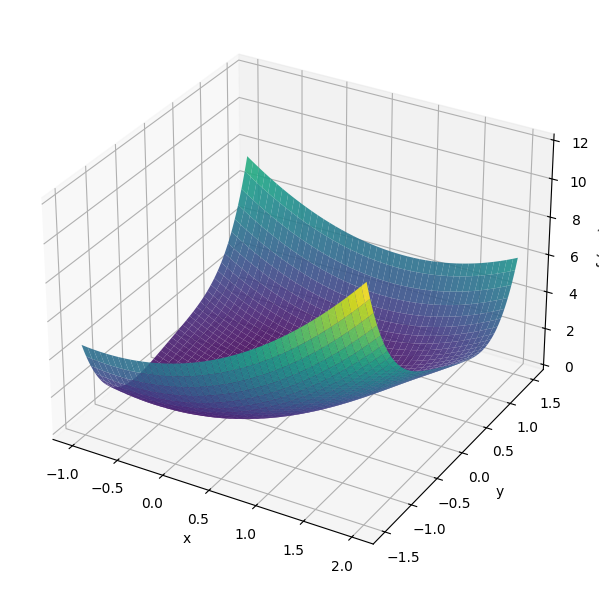

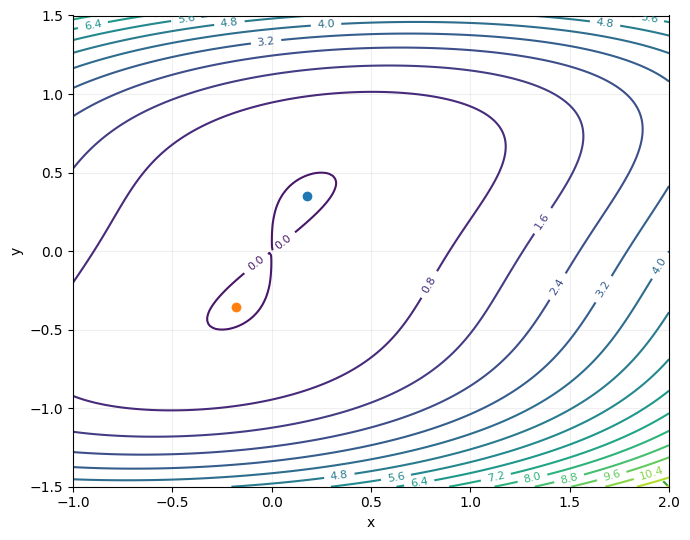

In [7]:
gx = np.linspace(X.lo, X.hi, 180)
gy = np.linspace(Y.lo, Y.hi, 180)
XX, YY = np.meshgrid(gx, gy)
ZZ = f3(XX, YY)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(XX, YY, ZZ, cmap="viridis", linewidth=0, antialiased=True, alpha=.9)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f₃(x,y)")
plt.tight_layout(); plt.savefig(OUT/"f3_surface.png", dpi=180); plt.show()

plt.figure(figsize=(7, 5.5))
cs = plt.contour(XX, YY, ZZ, levels=18)
plt.clabel(cs, inline=True, fontsize=8)
mins = [(1/(4*math.sqrt(2)), 1/(2*math.sqrt(2))), (-1/(4*math.sqrt(2)), -1/(2*math.sqrt(2)))]
for p in mins:
    plt.scatter(*p, marker="o")
plt.scatter(2, -1.5, marker="x", s=80)
plt.xlabel("x"); plt.ylabel("y"); plt.grid(alpha=.2); plt.tight_layout()
plt.savefig(OUT/"f3_contour.png", dpi=180); plt.show()


## 4. Итоговое сравнение

,Функция,Метод,d_H
0,f₁,Естественная,27.000000
1,f₁,Эквивалентная,4.000000
2,f₂,Естественная,0.000000
3,f₂,Baumann,0.000000
4,f₃,Естественная,2.984375
5,f₃,Эквивалентная,0.000000
6,f₃,Дробление по x,2.734375


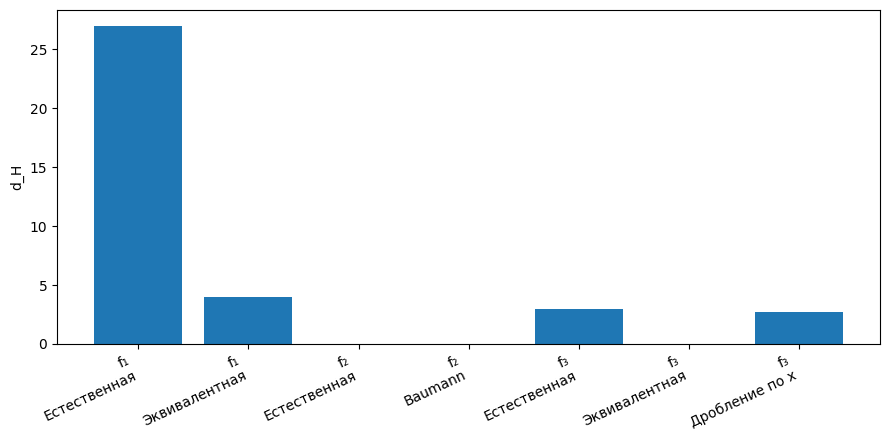

In [8]:
best = pd.DataFrame([
    ["f₁", "Естественная", hausdorff(nat1, true1)],
    ["f₁", "Эквивалентная", hausdorff(eq1, true1)],
    ["f₂", "Естественная", hausdorff(nat2, true2)],
    ["f₂", "Baumann", hausdorff(bic2, true2)],
    ["f₃", "Естественная", hausdorff(nat3, true3)],
    ["f₃", "Эквивалентная", hausdorff(eq3, true3)],
    ["f₃", "Дробление по x", hausdorff(split_x, true3)],
], columns=["Функция", "Метод", "d_H"])
display(best)

labels = [f"{a}\n{b}" for a,b in zip(best["Функция"], best["Метод"])]
plt.figure(figsize=(9,4.5))
plt.bar(labels, best["d_H"])
plt.ylabel("d_H"); plt.xticks(rotation=25, ha="right"); plt.tight_layout()
plt.savefig(OUT/"hausdorff_compare.png", dpi=180)
plt.show()
